In [1]:
!pip install duckdb seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.4/24.4 MB 137.7 MB/s  0:00:00 eta 0:00:01


In [2]:
import duckdb
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
con = duckdb.connect()
con.execute("SET memory_limit='300MB'")
con.execute("SET temp_directory='/tmp/duckdb_tmp'")
con.execute("SET threads=1")

df = con.execute("""
    SELECT "Complaint Type" AS type,
           month(try_strptime("Created Date", '%m/%d/%Y %I:%M:%S %p')) AS month,
           count(*) AS n
    FROM read_csv('311_only_2024.csv', header=true, all_varchar=true)
    WHERE lower("Complaint Type") LIKE '%noise%'
      AND year(try_strptime("Created Date", '%m/%d/%Y %I:%M:%S %p')) = 2024
    GROUP BY 1, 2
""").df()

print(df.groupby('type')['n'].sum().sort_values(ascending=False))
print('total noise complaints:', df['n'].sum())

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

type
Noise - Residential         379297
Noise - Street/Sidewalk     163002
Noise - Commercial           68347
Noise                        55522
Noise - Vehicle              48834
Noise - Helicopter           28686
Noise - Park                  8279
Noise - House of Worship      1296
Name: n, dtype: int64
total noise complaints: 753263


In [4]:
month_names = ['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec']

counts = df.pivot(index='type', columns='month', values='n').fillna(0).astype(int)
counts = counts.reindex(columns=range(1, 13), fill_value=0)
counts.columns = month_names

pct = counts.div(counts.sum(axis=0), axis=1) * 100

order = counts.sum(axis=1).sort_values(ascending=False).index
counts, pct = counts.loc[order], pct.loc[order]
pct.index = pct.index.str.replace('Noise - ', '', regex=False)

print(counts.sum(axis=0).to_string())
pct.round(1)

Jan    38677
Feb    39977
Mar    50930
Apr    55813
May    68280
Jun    75530
Jul    65374
Aug    63392
Sep    87960
Oct    77010
Nov    63753
Dec    66567


,Jan,Feb,Mar,Apr,May,Jun,Jul,Aug,Sep,Oct,Nov,Dec
type,,,,,,,,,,,,
Residential,57.1,53.8,48.9,45.3,43.7,41.1,41.5,42.3,51.8,50.2,61.3,71.2
Street/Sidewalk,9.4,11.2,14.9,17.6,22.6,32.8,34.5,32.5,24.6,23.7,14.5,7.3
Commercial,11.0,11.4,12.5,11.4,10.5,8.0,7.1,8.2,8.3,8.6,8.0,7.2
Noise,10.9,11.0,9.3,9.5,8.4,5.3,5.3,6.4,6.3,7.2,7.2,5.9
Vehicle,6.2,6.5,8.0,9.9,9.0,6.9,6.2,6.8,5.5,5.6,4.6,3.6
Helicopter,5.0,5.7,5.5,4.9,4.1,3.7,3.6,2.1,2.1,3.3,3.8,4.3
Park,0.2,0.4,0.7,1.2,1.5,2.0,1.6,1.7,1.2,1.1,0.5,0.2
House of Worship,0.1,0.1,0.1,0.2,0.2,0.2,0.1,0.1,0.2,0.3,0.1,0.2


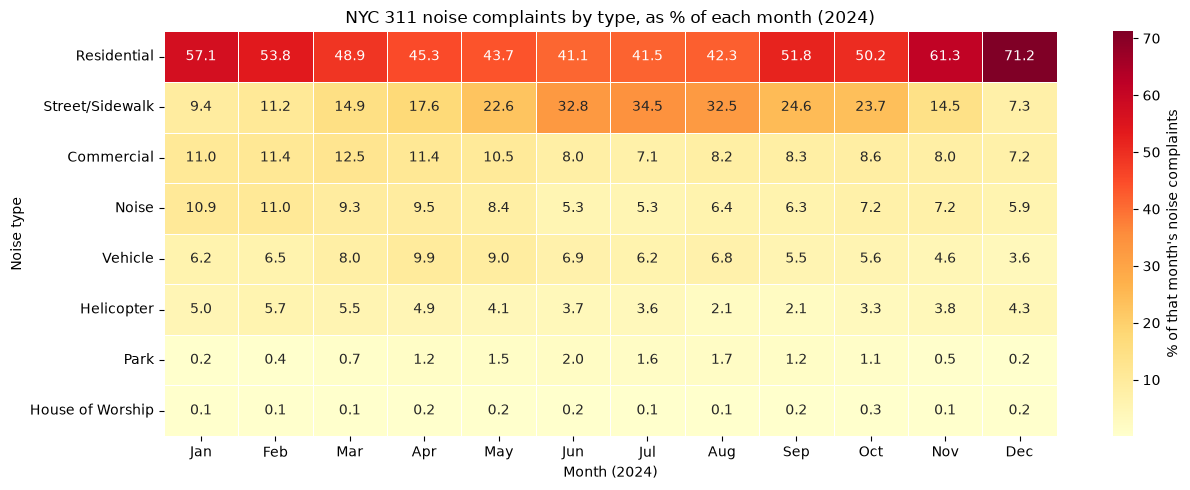

In [5]:
fig, ax = plt.subplots(figsize=(13, 5))
sns.heatmap(
    pct, annot=True, fmt='.1f', cmap='YlOrRd',
    cbar_kws={'label': "% of that month's noise complaints"},
    linewidths=0.5, ax=ax,
)
ax.set_title('NYC 311 noise complaints by type, as % of each month (2024)')
ax.set_xlabel('Month (2024)')
ax.set_ylabel('Noise type')
plt.tight_layout()
plt.savefig('noise_heatmap.png', dpi=200)
plt.show()

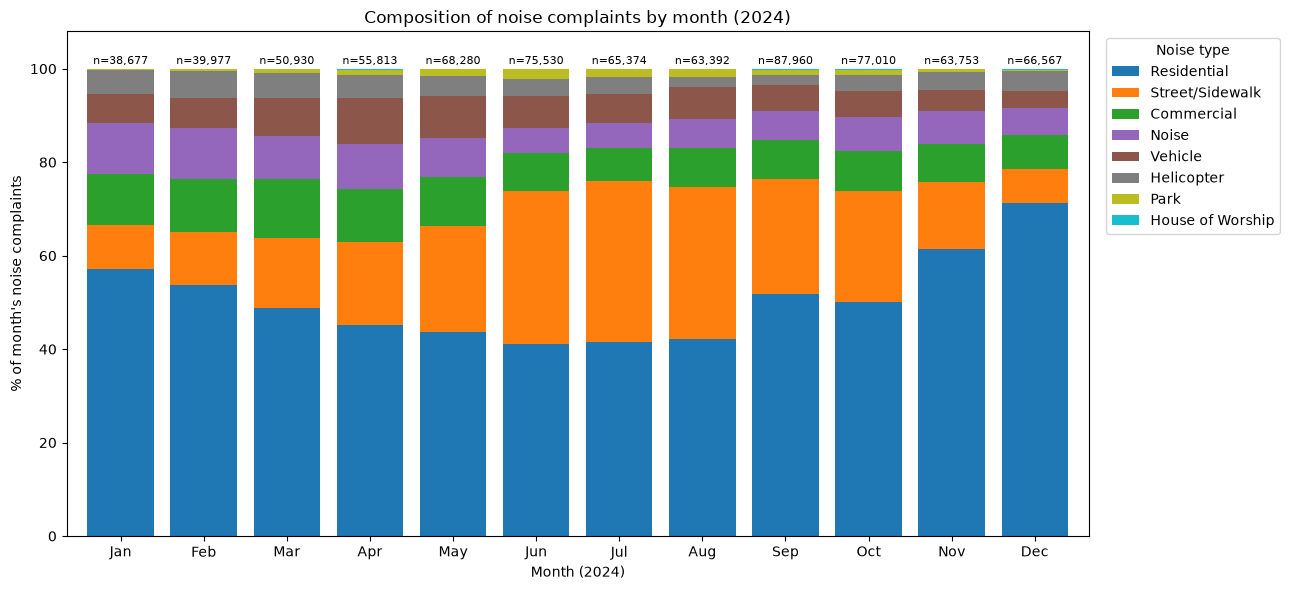

In [6]:
ax = pct.T.plot(kind='bar', stacked=True, figsize=(13, 6), colormap='tab10', width=0.8)
totals = counts.sum(axis=0)
for i, m in enumerate(pct.columns):
    ax.text(i, 101, f'n={totals[m]:,}', ha='center', fontsize=8)
ax.set_ylim(0, 108)
ax.set_ylabel("% of month's noise complaints")
ax.set_xlabel('Month (2024)')
ax.set_title('Composition of noise complaints by month (2024)')
ax.legend(title='Noise type', bbox_to_anchor=(1.01, 1), loc='upper left')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('noise_stacked.png', dpi=200)
plt.show()